# Teorema do Limite Central

**Autor**: Carlos Gabriel de Oliveira Campos

**Professor**: Dr. Daniel Roberto Cassar

O teorema do limite central afirma que dado um conjunto de simulações que seguem uma mesma distribuição — de variância finita e cujos valores são independentes entre si —, quanto maior o número de amostras, a distribuição dos valores de média das simulações tende a seguir uma distribuição normal. 

---

## Função suporte

Fornecida pelo professor Daniel de Probabilidade e Estatística [1]. 

In [36]:
import numpy as np
from math import pi
from numpy import exp
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt


def dist_normal_pdf(x, media, desvio_padrao):
    """Computa a pdf de uma distribuição normal."""

    preexp = 1 / (desvio_padrao * (2 * pi) ** (1 / 2))
    exp_ = exp(-(1 / 2) * ((x - media) / desvio_padrao) ** 2)
    densidade_prob = preexp * exp_

    return densidade_prob

## Distribuição Normal

Afinal, o que é uma distribuição normal? O que há de tão especial sobre ela?

A dsitribuição normal, também conhecida como distribuição gaussiana, é uma distribuição de probabilidade contínua que apresenta simetria em torno de sua média, sendo que valores próximos a essa média apresentam uma maior probabilidade. Uma distribuição de valores que segue esse comportamento pode ser representada pela notação $X \sim \mathcal{N}(\mu, \sigma^2)$, em que $\mu$ e $\sigma^2$ indicam a média e a variância, respectivamente, sendo que ela é definida matematicamente conforme 

$$
f(x\,|\,\mu,\sigma) = \frac{1}{\sigma \sqrt{2 \pi}} \exp \left( -\frac{1}{2} \left( \frac{x - \mu}{\sigma} \right)^2 \right)
$$


Mais notavelmente, essa distribuição tem seu formato extremamente reconhecido nas áreas da estatística, o qual assemelha-se a de um sino (código fornecido pelo professor Daniel [1]).

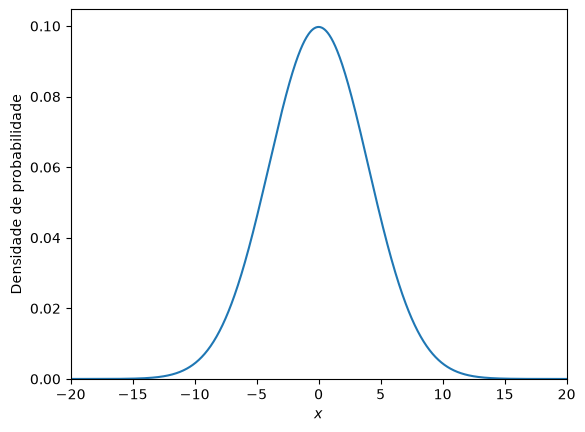

In [2]:
XMIN = -20
XMAX = 20

x = np.linspace(XMIN, XMAX, 1000)
y = dist_normal_pdf(x=x, media=0, desvio_padrao=4)

eixo = sns.lineplot(x=x, y=y)

eixo.set_xlim([XMIN, XMAX])
eixo.set_ylim(bottom=0)

eixo.set_xlabel("$x$")
eixo.set_ylabel("Densidade de probabilidade");

Investiguemos como ela se parece com diferentes parâmetros (código adaptado do material do professor Daniel [1]).

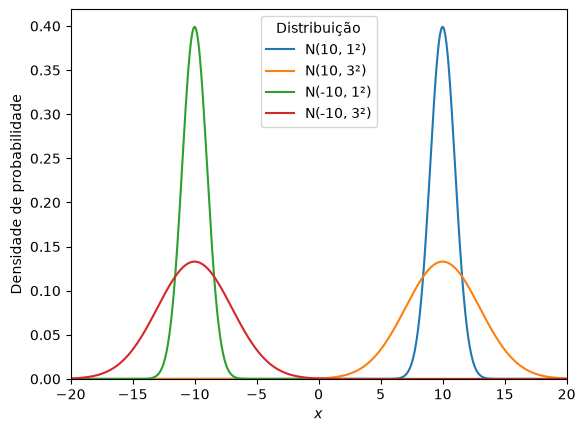

In [3]:
MEDIAS_E_DESVIOS_PADROES = [
    (10, 1),
    (10, 3),
    (-10, 1),
    (-10, 3)
]

x = np.linspace(XMIN, XMAX, 1000)

dados = []

for media, desvio_padrao in MEDIAS_E_DESVIOS_PADROES:
    y = dist_normal_pdf(x, media, desvio_padrao)
    df = pd.DataFrame(
        {
            "x": x,
            "y": y,
            "Distribuição": f"N({media}, {desvio_padrao}²)",
        }
    )
    dados.append(df)

df = pd.concat(dados)

eixo = sns.lineplot(data=df, x="x", y="y", hue="Distribuição")

eixo.set_xlim([XMIN, XMAX])
eixo.set_ylim(bottom=0)

eixo.set_xlabel("$x$")
eixo.set_ylabel("Densidade de probabilidade");

Veja, a média desloca a distribuição pelo eixo x, ao passo que o desvio padrão define o quão concentrada ou dispersa a distribuição estará ao redor da média. 

No mais, outra grande propriedade da distribuição normal é apresentar 68% dos dados a até um desvio padrão de distância da média, 95%, a até dois desvios padrões de distância, e 99.7%, a até três desvios padrões de distância, como mostra a seguinte figura.

<figure align="center">
   <img src="pctg_normal_dist.png" alt="Distribuição Normal" height="400px">

  <figcaption style="font-size: 0.9em; margin-top: 5px;"> 
  Fonte: https://www.geeksforgeeks.org/maths/normal-distribution/ </figcaption>
</figure>


## Entendo o Teorema

Certo, mas como essa distribuição se relaciona ao Teorema do Limite Central? 

O Teorema do Limite Central (TLC) afirma que dado um conjunto de amostras que seguem uma mesma distribuição — de variância finita e cujos valores são independentes entre si —, quanto maior o número de amostras, a distribuição dos valores de média das amostras tende a seguir uma *distribuição normal*.

Assim, podem ser indentificadas 3 premissas-base para esse teorema, sendo que $X_i$ representa os valores da distribuição populacional:

1. Independência entre os valores de $X_i$;
2. Todas as amostras seguem a mesma distribuição populacional;
3. A variância da distribuição populacional é finita.

De primeira, isso de fato é muita informação para compreender bem! Vamos construir o entendimento passo a passo:

## Nos guiando pela sorte de dados

A distribuição populacional é aquela que rege as amostras — que podem ser simulações ou eventos naturais, como o lançamento de dados! Nesse contexto, $X_i$ é represetnado pelo resultado do dado. Em um dado honesto, cada resultado é equiprovável, logo, em um dado de 6 faces, cada face tem $\dfrac{1}{6}$ de probabilidade. Vamos realizar e visualizar simulações!

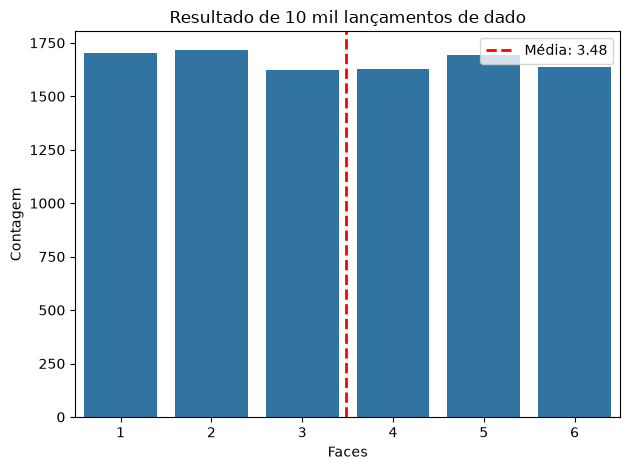

In [74]:
def lanca_dados(num_lancamentos: int, pesos=None, mostra_fig=False) -> float:
    """Retorna média de resultados de N lançamentos de 1 dado."""
    
    faces = np.arange(1, 7)
    
    if pesos:
        x = np.random.choice(a=faces, size=num_lancamentos, p=pesos)
    else:
        x = np.random.choice(a=faces, size=num_lancamentos)

    if mostra_fig:
        eixo = sns.countplot(x=x)

        eixo.axvline(x.mean() - 1, color="red", linestyle="--", linewidth=2, label=f"Média: {x.mean():.2f}")
        eixo.legend()

        eixo.set(
            ylabel="Contagem",
            xlabel="Faces",
            title=f"Resultado de {num_lancamentos// 1000} mil lançamentos de dado"
        )
        plt.tight_layout()
        plt.show()

    return x.mean()

media = lanca_dados(10_000, mostra_fig=True)

Como era de se esperar, vimos uma contagem muito semelhante entre todas os faces, e o valor da média aproximou-se muito do valor esperado para essa distribuição discreta, que é de 3.5. Agora, façamos um experimento com 10 mil amostras de 10 mil lançamentos de dados em que registramos a média de cada amostra, apresentand ao final a distribuição do valor dessas médias.

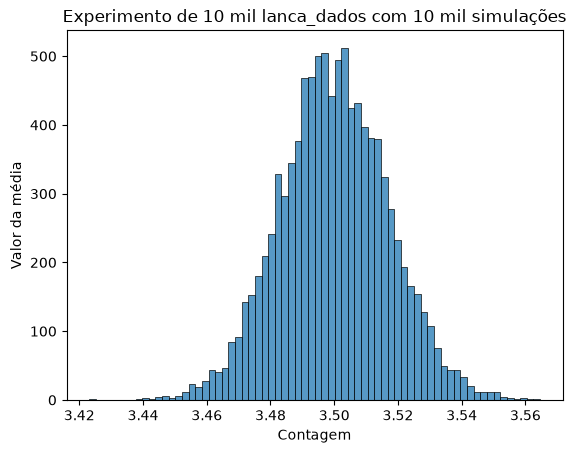

In [52]:
def experimento(
    distribuicao_populacional,
    tamanho_amostragem: int,
    num_simulacoes: int,
    **kwargs
    ) -> None:
    medias = []
    for _ in range(tamanho_amostragem):
        media = distribuicao_populacional(num_simulacoes, **kwargs)
        medias.append(media)

    plt.figure()
    eixo = sns.histplot(medias)

    titulo = (
        f"Experimento de {tamanho_amostragem // 1_000} mil "
        f"{distribuicao_populacional.__name__} "
        f"com {num_simulacoes // 1_000} mil simulações"
    )
    eixo. set(
        title=titulo,
        xlabel="Contagem",
        ylabel="Valor da média"
    )
    plt.show()

experimento(lanca_dados, 10_000, 10_000)

Podemos muito enxergar a formação de uma distribuição normal!! É sobre isso de que se trata o TLC: 

- Definimos uma distribuição (lançamento de dados)
- Realizamos simulações dessas distribuição (uma amostra - a função `lanca_dados`)
- Geramos várias dessas amostras (função `experimento`)
- Verificamos a média de cada uma delas (plotamos as médias)

Outro ponto interessante é que esse resultado independe da "honestidade" dos dados. Por exemplo, simulemos um dado cuja porbabilidade correspondente às suas faces seja:

1: 5% 
2:30%
3:10%
4: 13%
5: 5%
6: 37%

Vejamos qual é a média dos resultados para esse novo dado viciado (de acordo com a Lei dos Grandes Números [2]) a partir de 10 mil simulações!

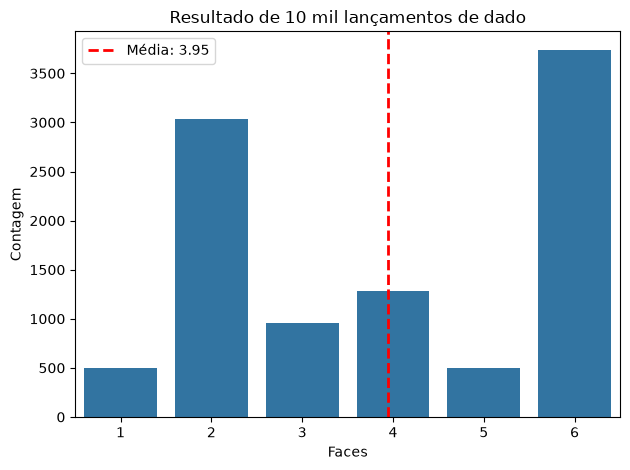

In [55]:
pesos_viciados = [0.05, 0.3, 0.1, 0.13, 0.05, 0.37]
lanca_dados(num_lancamentos=10_000, pesos=pesos, mostra_fig=True);

Agora façamos um experimento com 10 mil dessas amostras

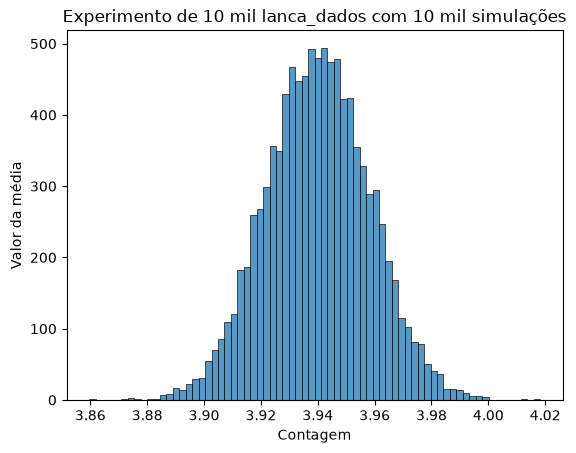

In [61]:
experimento(
    distribuicao_populacional=lanca_dados,
    num_simulacoes=10_000,
    tamanho_amostragem=10_000,
    pesos=pesos_viciados
    )

Monstro: Mímico.
O Teorema do Limite Central é importantíssimo para probabilidade e estatística;
em especial, é a base de diversos testes de hipóteses. Sua tarefa é se informar sobre
esse teorema, explicá‑lo com suas palavras de maneira clara e explorá‑lo através de
simulações em Python, com gráficos. Sua exploração deve incluir:
• Pelo menos três distribuições de origem claramente não normais (por exemplo,
exponencial, uniforme e uma distribuição bimodal).
• A evolução da distribuição das médias amostrais conforme o tamanho da amostra
𝑛 aumenta.
• A comparação de cada histograma do passo anterior com a curva normal prevista
pelo teorema, com média 𝜇 e desvio padrão 𝜎/√𝑛.
Desafio opcional: repita a simulação com a distribuição de Cauchy. O que acon
tece? Explique por que o teorema não se aplica nesse caso.

## Outras distribuições

Além do ato de lançar dados, podemos nos guiar por este conceito por meio de outras distribuições, até mesmo contínuas, como a distribuição de poisson! Vamos simulá-la para ver como ela se parece.

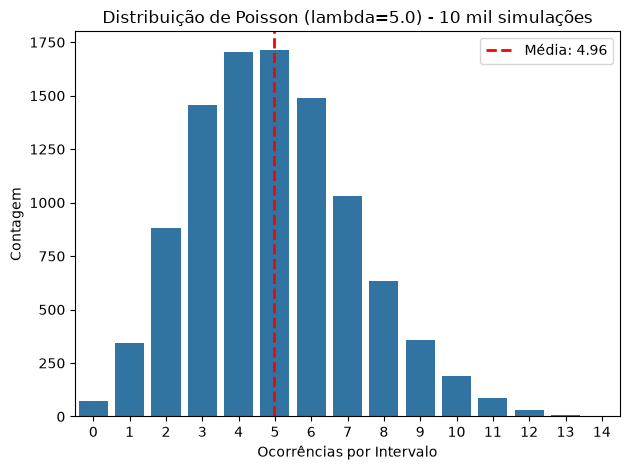

Média da amostra: 4.9645


In [76]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

def simula_poisson(num_lancamentos: int, lam=5.0, mostra_fig=False) -> float:
    """Simula N eventos de uma distribuição de Poisson e retorna a média."""
    
    x = np.random.poisson(lam=lam, size=num_lancamentos)
    
    if mostra_fig:
        plt.figure()
        # countplot ou histplot para variáveis discretas
        eixo = sns.countplot(x=x)
        
        eixo.axvline(x.mean() - x.min(), color="red", linestyle="--", linewidth=2, label=f"Média: {x.mean():.2f}")
        eixo.legend()
        
        eixo.set(
            ylabel="Contagem",
            xlabel="Ocorrências por Intervalo",
            title=f"Distribuição de Poisson (lambda={lam}) - {num_lancamentos // 1_000} mil simulações"
        )
        plt.tight_layout()
        plt.show()

    return x.mean()

# 1. Testando a simulação individual
media_poisson = simula_poisson(10_000, lam=5.0, mostra_fig=True)
print(f"Média da amostra: {media_poisson}")

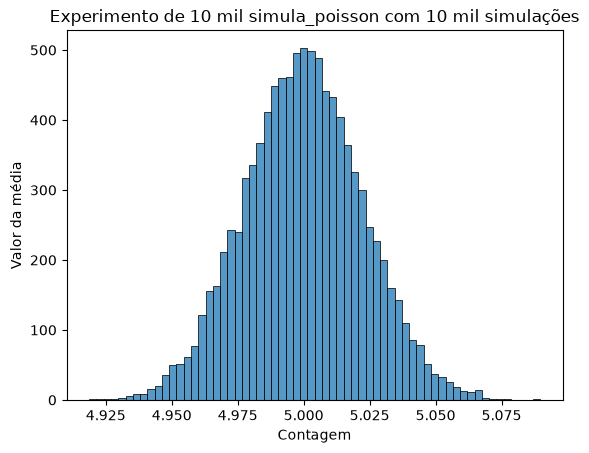

In [77]:
experimento(
    simula_poisson,
    10_000,
    10_000
)

## Referências

[1] CASSAR, Daniel R. Material de aula **LMA-203 7.0 - Distribuição de probabilidades contínuas** para a disciplina de Estatística, 2026.

## Uso de IA neste trabalho

A ferramente de inteligência artificial Gemini foi utilizada para auxiliar a:

- 

<div style="width: 100%; text-align: center; margin-bottom: 20px;">
  <img src="../elementos/rodape_eleicao.png" alt="Rodapé" style="max-width: 100%; height: auto;">
</div>